In [50]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage.exposure import match_histograms

# Some helper functions

In [51]:
def display_image(img, cmap=None):
    plt.figure(figsize=(20, 10))
    if cmap is None:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap)
    plt.axis('off')
    plt.show()

def display_two_images(img, img2, cmap=None):
    plt.figure(figsize=(20, 10))
    plt.subplot(1, 2, 1)
    if cmap is None:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    if cmap is None:
        plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img2, cmap=cmap)
    plt.axis('off')
    plt.show()

In [52]:
# https://www.geeksforgeeks.org/dsa/minimum-distance-from-a-point-to-the-line-segment-using-vectors/
def distance(line, E) : 
    A = line[0], line[1]
    B = line[2], line[3]
    
    # vector AB 
    AB = [None, None]; 
    AB[0] = B[0] - A[0]; 
    AB[1] = B[1] - A[1]; 

    # vector BP 
    BE = [None, None];
    BE[0] = E[0] - B[0]; 
    BE[1] = E[1] - B[1]; 

    # vector AP 
    AE = [None, None];
    AE[0] = E[0] - A[0];
    AE[1] = E[1] - A[1]; 

    # Variables to store dot product 

    # Calculating the dot product 
    AB_BE = AB[0] * BE[0] + AB[1] * BE[1]; 
    AB_AE = AB[0] * AE[0] + AB[1] * AE[1]; 

    # Minimum distance from 
    # point E to the line segment 
    reqAns = 0; 

    # Case 1 
    if (AB_BE > 0) :

        # Finding the magnitude 
        y = E[1] - B[1]; 
        x = E[0] - B[0]; 
        reqAns = np.sqrt(x * x + y * y); 

    # Case 2 
    elif (AB_AE < 0) :
        y = E[1] - A[1]; 
        x = E[0] - A[0]; 
        reqAns = np.sqrt(x * x + y * y); 

    # Case 3 
    else:

        # Finding the perpendicular distance 
        x1 = AB[0]; 
        y1 = AB[1]; 
        x2 = AE[0]; 
        y2 = AE[1]; 
        mod = np.sqrt(x1 * x1 + y1 * y1); 
        reqAns = abs(x1 * y2 - y1 * x2) / mod; 
    
    return reqAns; 

# Loading the images

In [53]:
image_list = [
    ['images/2021-10-06T03.00.00.000KRN_small.jpeg', 'images/2021-10-06T02.59.00.000KRN_small.jpeg'], # the best one
    ['images/two meteorites.jpg', 'images/2022-02-28T03.11.00.000KRN_small.jpeg'],
    ['images/2022-02-28T03.03.00.000KRN_small.jpeg', 'images/2022-02-28T03.04.00.000KRN_small.jpeg', 'images/2022-02-28T03.05.00.000KRN_small.jpeg'],
    ['images/2022-02-28T03.09.00.000KRN_small.jpeg', 'images/2022-02-28T03.10.00.000KRN_small.jpeg', 'images/2022-02-28T03.11.00.000KRN_small.jpeg'],
    ['images/2022-02-28T03.25.00.000KRN_small.jpeg', 'images/2022-02-28T03.26.00.000KRN_small.jpeg', 'images/2022-02-28T03.27.00.000KRN_small.jpeg'],
    # ['images/2022-02-28T03.11.00.000KRN_small.jpeg', 'images/2022-02-28T03.12.00.000KRN_small.jpeg', 'images/2022-02-28T03.13.00.000KRN_small.jpeg'], # actually no meteorite just camera changed expouser and I want to see how it performs on that
    ['images/2022-02-28T03.45.00.000KRN_small.jpeg', 'images/2022-02-28T03.44.00.000KRN_small.jpeg', 'images/2022-02-28T03.43.00.000KRN_small.jpeg', 'images/2022-02-28T03.42.00.000KRN_small.jpeg', 'images/2022-02-28T03.41.00.000KRN_small.jpeg', 'images/2022-02-28T03.40.00.000KRN_small.jpeg', 'images/2022-02-28T03.39.00.000KRN_small.jpeg'] # maybe a plane?
]

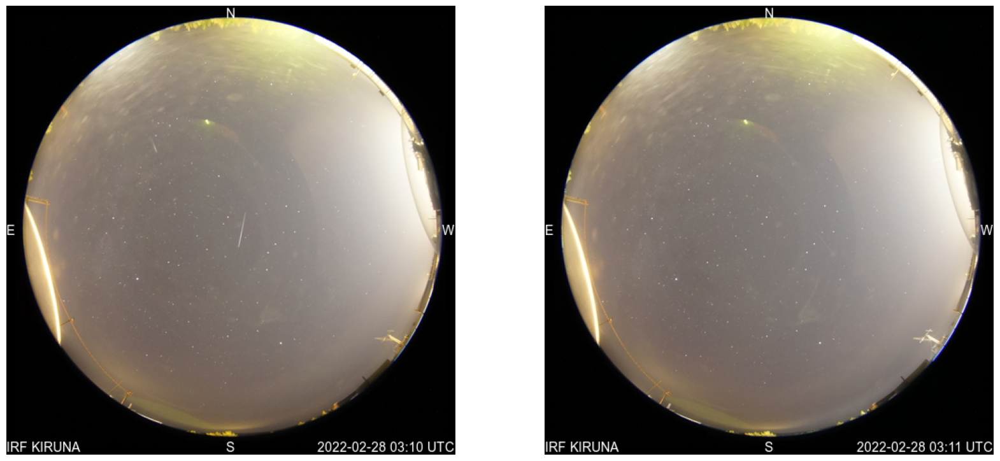

In [54]:
im_meteorite = cv2.imread('images/two meteorites.jpg')
im_no_meteorite = cv2.imread('images/2022-02-28T03.11.00.000KRN_small.jpeg')
display_two_images(im_meteorite, im_no_meteorite)

im_meteorite_gray = im_meteorite[0:, 0:, 0]
im_no_meteorite_gray = im_no_meteorite[0:, 0:, 0]

# Masking only the central part of the image

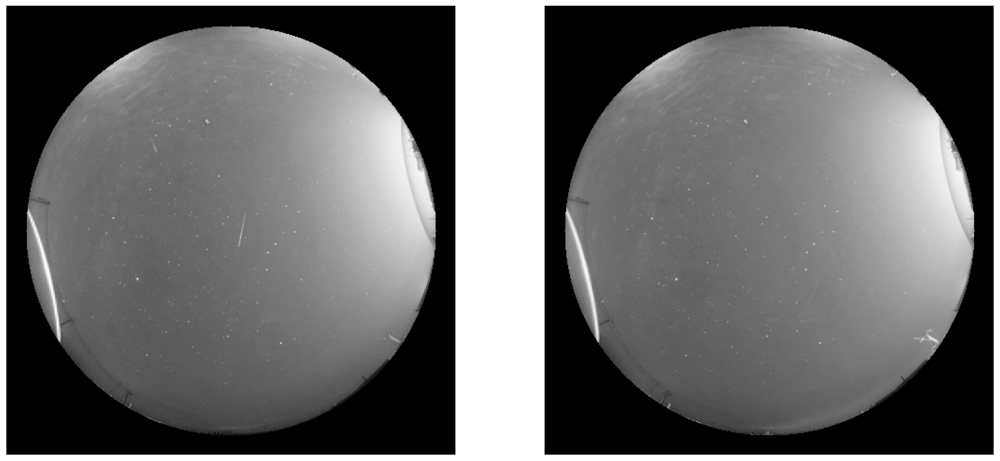

In [55]:
mask = np.zeros(im_meteorite_gray.shape[:2], dtype="uint8")
cv2.circle(mask, (int(im_meteorite_gray.shape[0]/2), int(im_meteorite_gray.shape[0]/2)), 220, 255, -1)
# mask = cv2.blur(mask, (25, 25))
im_meteorite_gray = cv2.bitwise_and(im_meteorite_gray, im_meteorite_gray, mask=mask)
im_no_meteorite_gray = cv2.bitwise_and(im_no_meteorite_gray, im_no_meteorite_gray, mask=mask)

display_two_images(im_meteorite_gray, im_no_meteorite_gray)

# Matching the histograms of both images

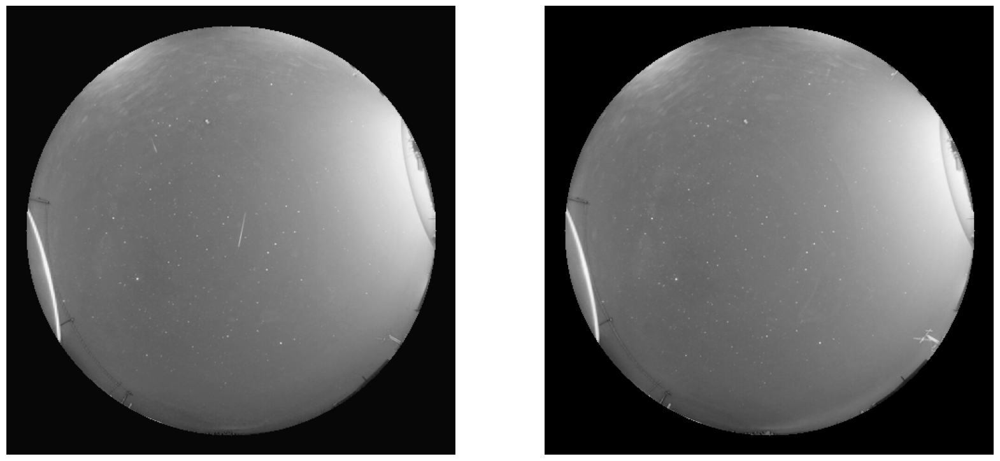

In [56]:
im_meteorite_gray = match_histograms(im_meteorite_gray, im_no_meteorite_gray)
im_meteorite_gray = np.clip(im_meteorite_gray, 0, 255).astype(np.uint8)

display_two_images(im_meteorite_gray, im_no_meteorite_gray)

# Making a defect map and substracting it from both of the images

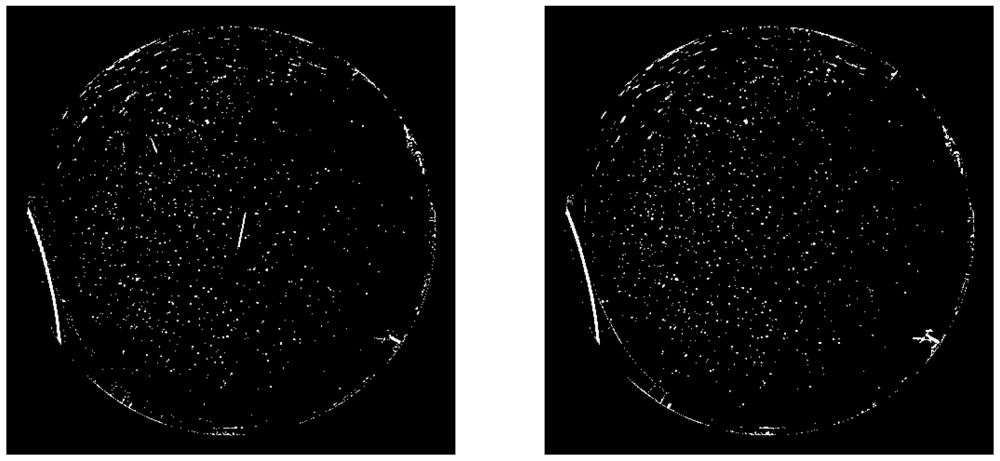

In [57]:
defects_meteorite = cv2.medianBlur(im_meteorite_gray, 7)
defects_no_meteorite = cv2.medianBlur(im_no_meteorite_gray, 7)

blur_meteorite = cv2.subtract(im_meteorite_gray, defects_meteorite)
blur_no_meteorite = cv2.subtract(im_no_meteorite_gray, defects_no_meteorite)

blur_meteorite = cv2.threshold(blur_meteorite, 5, 255, cv2.THRESH_BINARY)[1]
blur_no_meteorite = cv2.threshold(blur_no_meteorite, 5, 255, cv2.THRESH_BINARY)[1]

display_two_images(blur_meteorite, blur_no_meteorite)

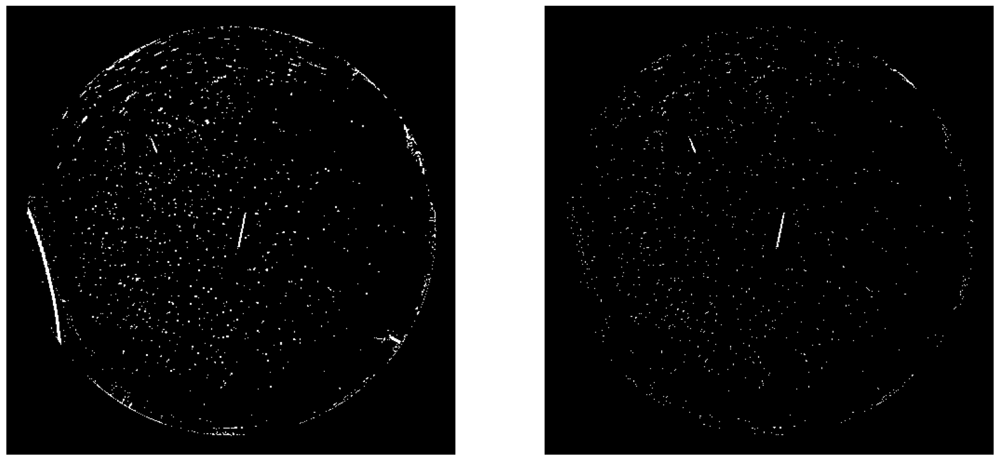

In [58]:
sub = cv2.subtract(blur_meteorite, blur_no_meteorite)
# _, thresh = cv2.threshold(sub, 10, 255, cv2.THRESH_OTSU)
display_two_images(blur_meteorite, cv2.medianBlur(sub, 1))

# Finding meteorites in all the noise

### Firstly using `cv2.connectedComponentsWithStats` to detect only bigger structures in the image

In [59]:
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(sub, connectivity=8)

max_area = np.percentile(stats[1:, cv2.CC_STAT_AREA], 99)

# only for displaying the results
possible_meteorite = np.zeros_like(sub)

for i in range(1, num_labels):  # Skip background
    area = stats[i, cv2.CC_STAT_AREA]
    if area >= max_area:
        possible_meteorite[labels == i] = 1


overlay = im_meteorite.copy()
overlay[possible_meteorite > 0] = (0, 0, 255)

### Then with the help of Hough lines finding only strait lines in the picture

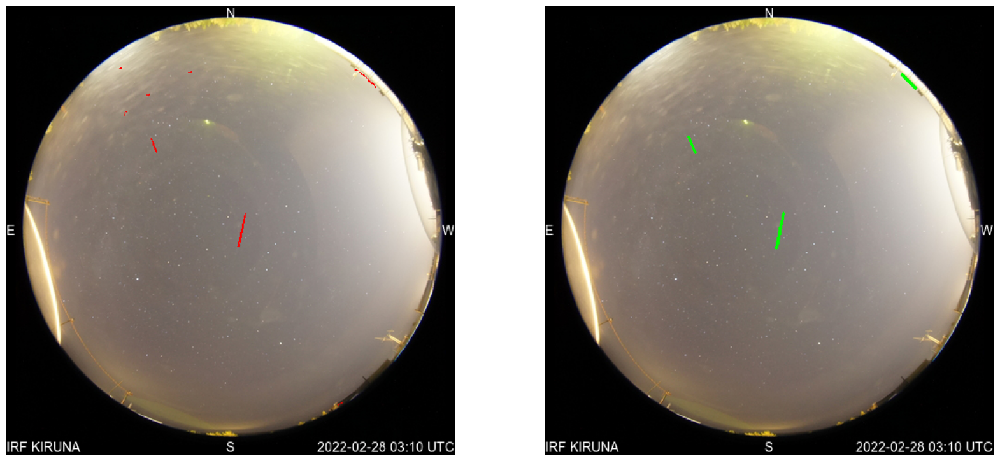

In [60]:
lines = cv2.HoughLinesP(
    sub,1,np.pi/180,20,minLineLength=5,maxLineGap=1
)

# only for displaying the results
tmp = im_meteorite.copy()

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line.reshape(-1)
        cv2.line(tmp, (x1, y1), (x2, y2), (0, 255, 0), 2)
else:
    print("No lines detected")

display_two_images(overlay, tmp)

### Matching the structures found using the last two methods and calculating the pixel variance to discern wether or not the thing is a meteorite

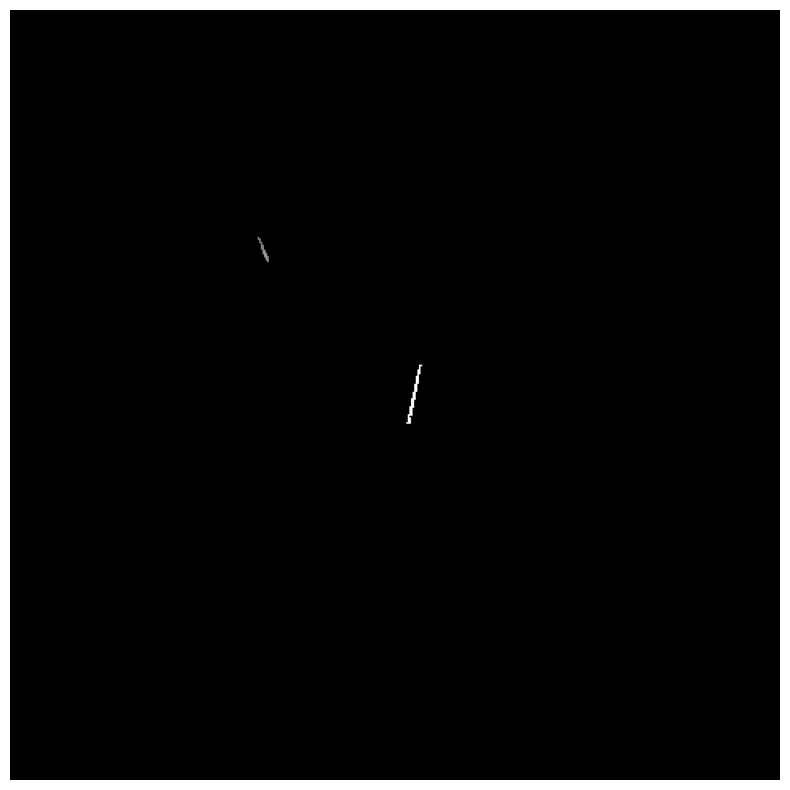

In [61]:
matched_ids = []
tolerance = 1

for line in lines:
    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        if area >= max_area and distance(line, centroids[i]) < tolerance:
            matched_ids.append(i)


possible_meteorite = [np.zeros_like(sub) for i in matched_ids]

j = 0
for i in matched_ids:
    area = stats[i, cv2.CC_STAT_AREA]
    if area >= max_area:
        possible_meteorite[j][labels == i] = 1
    j += 1


meteorites = [cv2.bitwise_and(im_meteorite_gray, im_meteorite_gray, mask=star) for star in possible_meteorite]

meteorites = [cv2.bitwise_and(im_meteorite_gray, im_meteorite_gray, mask=star) for star in possible_meteorite]

meteorites = [
    meteorite for meteorite in meteorites
    if meteorite[meteorite > 0].size > 0
    and np.var(meteorite[meteorite > 0]) >= 100
]

mask = np.zeros(sub.shape[:2], dtype="uint8")
for meteorite in meteorites:
    mask = cv2.add(mask, meteorite)

display_image(mask)

# And finally the function

In [62]:
def detect_meteorite(im_meteorite, im_no_meteorite, hough_threshold=25, hough_min_lenght=5, hough_max_gap=1, area_percentile=99, variance=100):
    """"""
    # using only the blue channel of the image
    im_meteorite_gray = im_meteorite[0:, 0:, 0]
    im_no_meteorite_gray = im_no_meteorite[0:, 0:, 0]
    
    # masking out only the central portion of the image
    mask = np.zeros(im_meteorite_gray.shape[:2], dtype="uint8")
    cv2.circle(mask, (int(im_meteorite_gray.shape[0]/2), int(im_meteorite_gray.shape[0]/2)), 220, 255, -1)
    # mask = cv2.blur(mask, (25, 25))
    im_meteorite_gray = cv2.bitwise_and(im_meteorite_gray, im_meteorite_gray, mask=mask)
    im_no_meteorite_gray = cv2.bitwise_and(im_no_meteorite_gray, im_no_meteorite_gray, mask=mask)

    # matching the brightnesses between the two images
    im_meteorite_gray = match_histograms(im_meteorite_gray, im_no_meteorite_gray)
    im_meteorite_gray = np.clip(im_meteorite_gray, 0, 255).astype(np.uint8)

    defects_meteorite = cv2.medianBlur(im_meteorite_gray, 7)
    defects_no_meteorite = cv2.medianBlur(im_no_meteorite_gray, 7)

    blur_meteorite = cv2.subtract(im_meteorite_gray, defects_meteorite)
    blur_no_meteorite = cv2.subtract(im_no_meteorite_gray, defects_no_meteorite)

    blur_meteorite = cv2.threshold(blur_meteorite, 5, 255, cv2.THRESH_BINARY)[1]
    blur_no_meteorite = cv2.threshold(blur_no_meteorite, 5, 255, cv2.THRESH_BINARY)[1]

    # subtracting both images
    sub = cv2.subtract(blur_meteorite, blur_no_meteorite)

    # drawing the first mask from the lines
    mask = np.zeros(sub.shape[:2], dtype="uint8")

    # finally using hough lines and connected components to figure out if there's a meteorite in the picture
    lines = cv2.HoughLinesP(
        image=sub, 
        rho=1, 
        theta=np.pi/180, 
        threshold=hough_threshold, 
        minLineLength=hough_min_lenght, 
        maxLineGap=hough_max_gap
    )

    num_meteorites = 0

    if lines is not None:        
        # for line in lines:
        #     x1, y1, x2, y2 = line.reshape(-1)
        #     cv2.line(mask_line, (x1, y1), (x2, y2), (255, 255, 255), 2)


        num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(sub, connectivity=8)
        max_area = np.percentile(stats[1:, cv2.CC_STAT_AREA], area_percentile)
        matched_ids = []
        tolerance = 1

        for line in lines:
            for i in range(1, num_labels):
                area = stats[i, cv2.CC_STAT_AREA]
                if area >= max_area and distance(line, centroids[i]) < tolerance:
                    matched_ids.append(i)


        possible_meteorite = [np.zeros_like(sub) for i in matched_ids]

        j = 0
        for i in matched_ids:
            area = stats[i, cv2.CC_STAT_AREA]
            if area >= max_area:
                possible_meteorite[j][labels == i] = 1
            j += 1


        meteorites = [cv2.bitwise_and(im_meteorite_gray, im_meteorite_gray, mask=star) for star in possible_meteorite]

        meteorites = [
            meteorite for meteorite in meteorites
            if meteorite[meteorite > 0].size > 0
            and np.var(meteorite[meteorite > 0]) >= variance
        ]

        mask = np.zeros(sub.shape[:2], dtype="uint8")
        for meteorite in meteorites:
            mask = cv2.add(mask, meteorite)

        num_meteorites = len(meteorites)
        
    else:
        print('No meteorites found')

    
    return mask, num_meteorites

fyi chatgpt wrote this function ('display_meteorite_results') just so I don't waste my time on displaying results

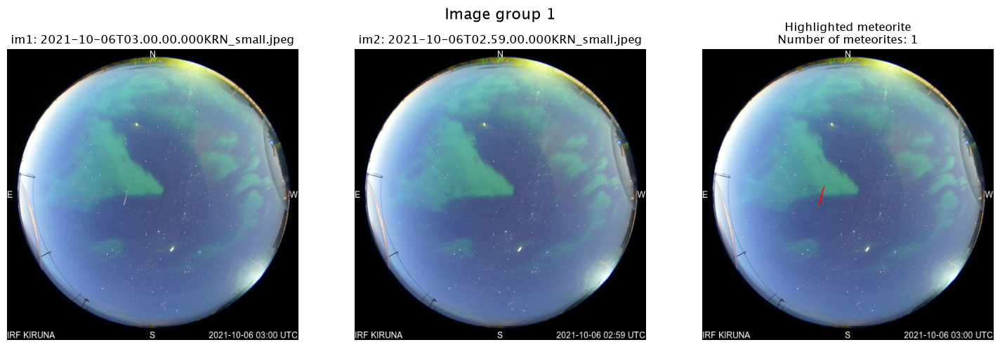

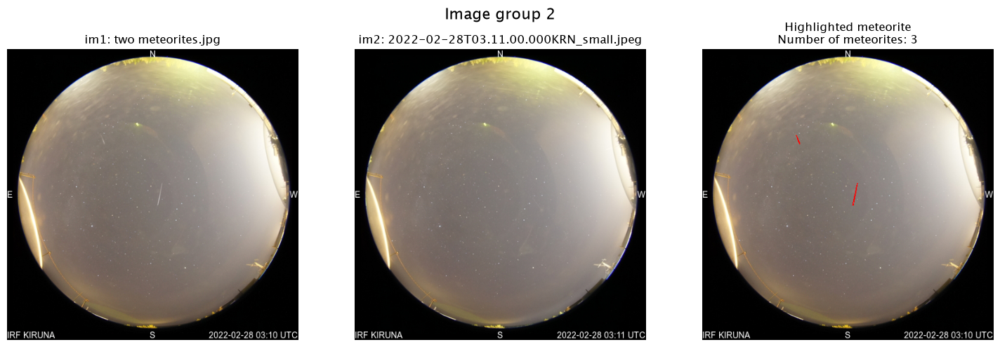

No meteorites found


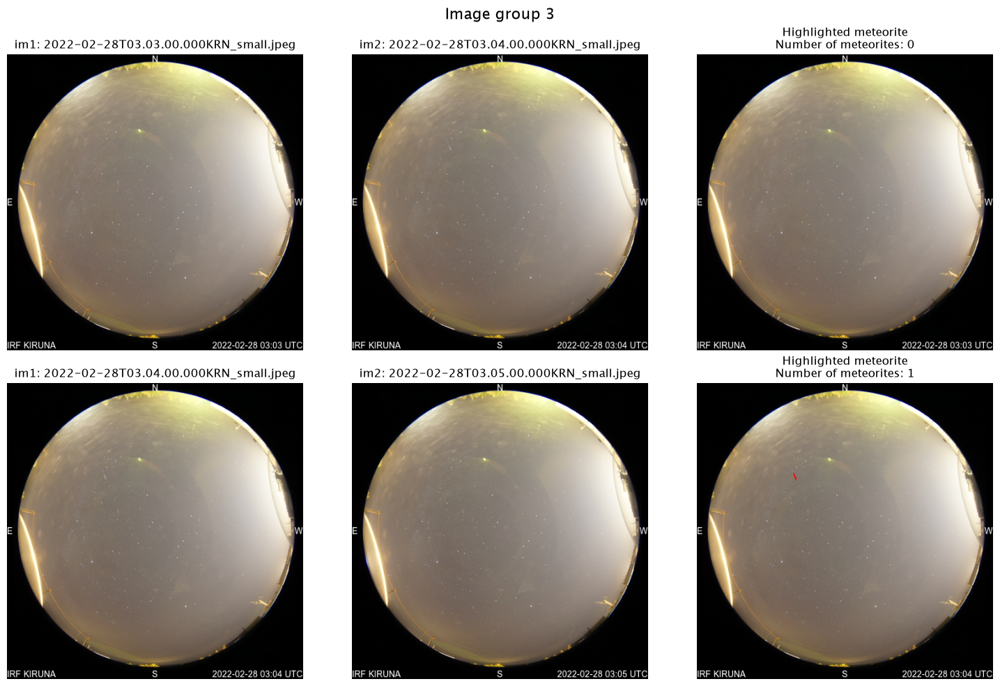

No meteorites found


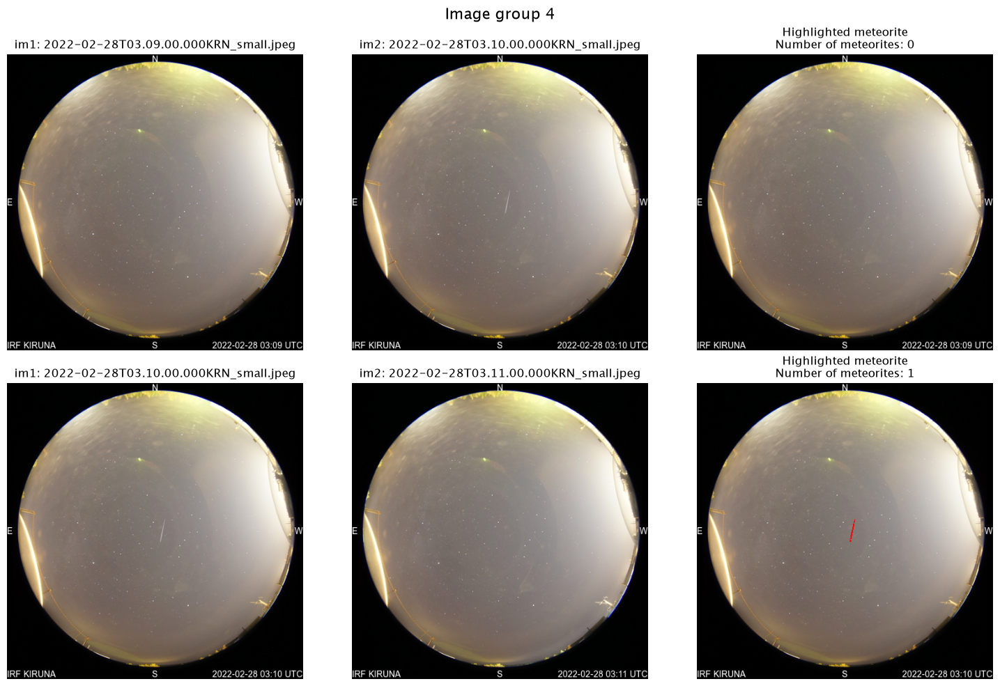

No meteorites found
No meteorites found


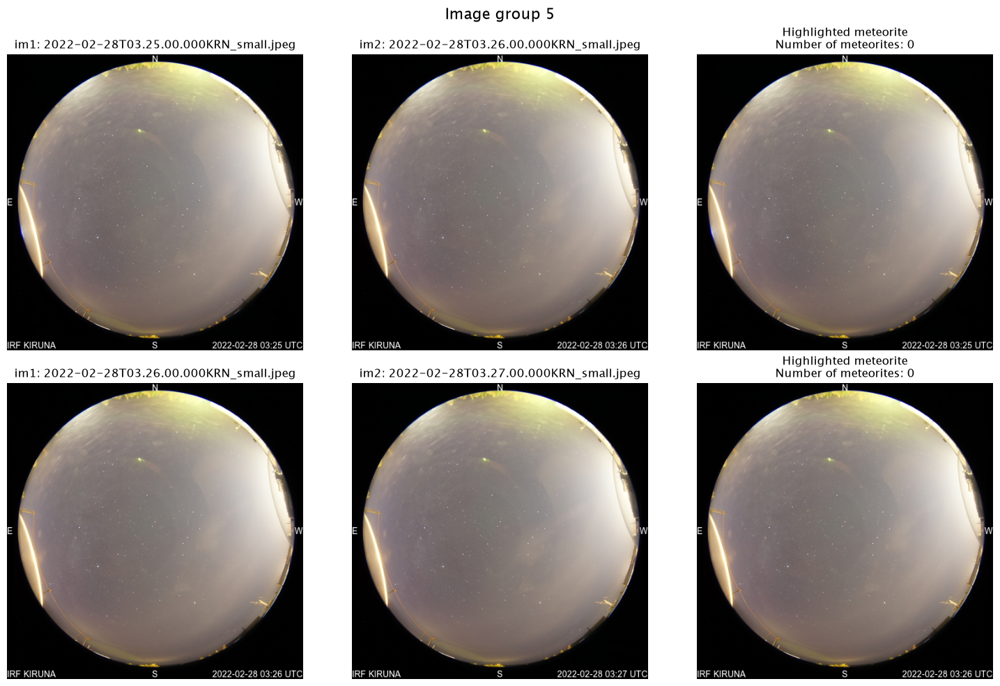

No meteorites found
No meteorites found
No meteorites found
No meteorites found


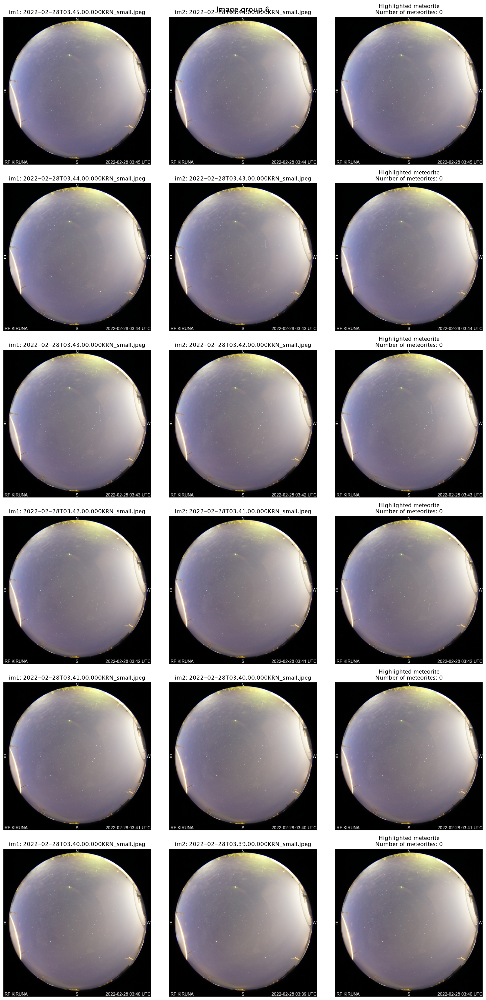

In [63]:
def display_meteorite_results(image_list):
    for group_idx, image_group in enumerate(image_list):
        n_pairs = len(image_group) - 1

        if n_pairs <= 0:
            continue

        fig, axes = plt.subplots(
            n_pairs, 3,
            figsize=(15, 5 * n_pairs),
            squeeze=False
        )

        fig.suptitle(
            f"Image group {group_idx + 1}",
            fontsize=16
        )

        for i in range(n_pairs):
            # Load consecutive images
            im1 = cv2.imread(image_group[i])
            im2 = cv2.imread(image_group[i + 1])

            if im1 is None or im2 is None:
                print(f"Could not load images: {image_group[i]}, {image_group[i + 1]}")
                continue

            # Convert BGR to RGB for matplotlib
            im1_rgb = cv2.cvtColor(im1, cv2.COLOR_BGR2RGB)
            im2_rgb = cv2.cvtColor(im2, cv2.COLOR_BGR2RGB)

            # Detect meteorite
            meteorite_mask, variance = detect_meteorite(im1, im2, 
                hough_threshold=20, 
                hough_min_lenght=5, 
                hough_max_gap=1, 
                area_percentile=99,
                variance=100
            )

            # Highlight detected pixels in red on the first image
            highlighted = im1_rgb.copy()
            highlighted[meteorite_mask > 0] = [255, 0, 0]

            # Display images
            axes[i, 0].imshow(im1_rgb)
            axes[i, 0].set_title(f"im1: {image_group[i].split('/')[-1]}")
            axes[i, 0].axis("off")

            axes[i, 1].imshow(im2_rgb)
            axes[i, 1].set_title(f"im2: {image_group[i + 1].split('/')[-1]}")
            axes[i, 1].axis("off")

            axes[i, 2].imshow(highlighted)
            axes[i, 2].set_title(
                f"Highlighted meteorite\nNumber of meteorites: {variance:.0f}"
            )
            axes[i, 2].axis("off")

        plt.tight_layout()
        plt.show()


display_meteorite_results(image_list)